In [1]:
# IMPORTS AND CONFIGURATION

import os
import re
import sys
import time
import random
import copy
import urllib.request
from pathlib import Path
from dataclasses import dataclass

import cv2
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score, roc_auc_score

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from IPython.display import FileLink, display

@dataclass
class PipelineConfig:
    seed = 42
    img_size = 384
    backbone_name = 'efficientnet_b3'
    num_classes = 5

    train_batch_size = 4
    accum_steps = 2
    val_batch_size = 4
    num_workers = 4
    epochs = 10
    lr = 2e-4
    weight_decay = 1e-4
    drop_rate = 0.3

    lambda_cls = 1.0
    lambda_ma = 0.40
    lambda_hemo = 0.40
    lambda_ex = 0.35

    recap_backbone = 'mobilenetv3_large_100'
    recap_img_size = 320
    recap_epochs = 7
    recap_lr = 3e-4
    recap_weight_decay = 1e-4
    recap_batch_size = 16
    recap_synth_prob = 0.5
    recap_real_bad_oversample = 6.0
    recap_lambda_reason = 0.5

    checkpoint_name: str = "netrasense_efficientnet_b3_best.pth"
    rlhf_checkpoint_name: str = "netrasense_efficientnet_b3_rlhf.pth"
    recap_checkpoint_name: str = "netrasense_recapture_gate.pth"
    kaggle_input_dir: Path = Path('/kaggle/input')
    test_image_default: str = "/kaggle/input/dr-test-image/images_dr.jpg"
    device: torch.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

CFG = PipelineConfig()
seed_everything(CFG.seed)

DR_CLASS_MAP = {
    0: ("No DR", "Normal fundus appearance."),
    1: ("Mild NPDR", "Microaneurysms only; early focal vascular permeability."),
    2: ("Moderate NPDR", "Multiple MAs, blot hemorrhages, and lipid exudates (<20 per quadrant)."),
    3: ("Severe NPDR", "ICDR 4-2-1 Rule: Pan-retinal hemorrhages (>=20 in 4 quadrants) / severe ischemia."),
    4: ("Proliferative DR", "Neovascularization (NVD/NVE) or preretinal/vitreous hemorrhage.")
}

In [2]:
# DATASET AND FOLDER MAPPING

def normalize_stem(val):
    s = Path(str(val)).stem.strip().lower()
    for suffix in ['_rgb', '_ma', '_hemo', '_mask', 'test', '_test']:
        s = s.replace(suffix, '')
    match = re.search(r'(\d+)', s)
    if match:
        return f"{int(match.group(1)):03d}"
    return s

FILTER_KEYWORDS = ('image-filter', 'image_filter', 'image filter', 'imagefilter', 'filter')
filter_csv_candidates = [c for c in CFG.kaggle_input_dir.rglob('*.csv') if any(k in str(c).lower() for k in FILTER_KEYWORDS)]
FILTER_CSV_PATH = filter_csv_candidates[0] if filter_csv_candidates else None
FILTER_ROOT = FILTER_CSV_PATH.parent if (FILTER_CSV_PATH is not None and FILTER_CSV_PATH.parent != CFG.kaggle_input_dir) else None

def is_filter_path(p):
    p = Path(p)
    if any(k in str(p).lower() for k in FILTER_KEYWORDS):
        return True
    return FILTER_ROOT is not None and (FILTER_ROOT == p or FILTER_ROOT in p.parents)

TEST_ONLY_KEYWORDS = ('bad-fundus', 'bad_fundus', 'bad fundus', 'badfundus', 'dr-test-image', 'dr_test_image', 'dr - test image')

def is_patent_path(p):
    return 'patent' in str(p).lower()

def is_test_only_path(p):
    return any(k in str(p).lower() for k in TEST_ONLY_KEYWORDS)

candidate_csvs = [c for c in CFG.kaggle_input_dir.rglob('*.csv') if not is_filter_path(c)]
if not candidate_csvs:
    raise FileNotFoundError("No main DR label CSV found under /kaggle/input.")

df_raw = pd.read_csv(candidate_csvs[0])
image_col = next((c for c in df_raw.columns if any(k in c.lower() for k in ['image', 'id', 'name'])), df_raw.columns[0])
label_col = next((c for c in df_raw.columns if any(k in c.lower() for k in ['retinopathy', 'grade', 'label'])), df_raw.columns[1])

df = df_raw[[image_col, label_col]].dropna().copy()
df.columns = ["image_name", "label"]
df["label"] = df["label"].astype(int)
df["clean_id"] = df["image_name"].apply(normalize_stem)

all_images = [p for p in CFG.kaggle_input_dir.rglob('*') if p.suffix.lower() in ['.jpg', '.jpeg', '.png', '.tif']]

NAME_INDEX_FILTER, NAME_INDEX_MAIN = {}, {}
for p in all_images:
    if is_test_only_path(p):
        continue
    (NAME_INDEX_FILTER if is_filter_path(p) else NAME_INDEX_MAIN).setdefault(p.name.lower(), str(p))

rgb_index, ma_index, hemo_index = {}, {}, {}

for p in all_images:
    if is_filter_path(p) or is_test_only_path(p):
        continue
    p_str = str(p).lower()
    if 'images_dr' in p.name.lower() or 'dr-test-image' in p_str or 'dr - test image' in p_str:
        continue

    parts_lower = [part.lower() for part in p.parts]
    cid = normalize_stem(p.stem)
    if any('hemorrhage' in part or 'hemo' in part for part in parts_lower) or 'hemo' in p_str:
        hemo_index[cid] = str(p)
    elif any('microaneurysm' in part or 'ma' == part for part in parts_lower) or 'microaneurysm' in p_str:
        ma_index[cid] = str(p)
    elif any('rgb' in part for part in parts_lower) or 'rgb' in p_str:
        rgb_index[cid] = str(p)
    else:
        if cid not in rgb_index:
            rgb_index[cid] = str(p)

df['rgb_path'] = df['clean_id'].map(rgb_index)
df['ma_path'] = df['clean_id'].map(ma_index)
df['hemo_path'] = df['clean_id'].map(hemo_index)

valid_df = df.dropna(subset=['rgb_path']).reset_index(drop=True)
train_df, val_df = train_test_split(valid_df, test_size=0.20, stratify=valid_df['label'], random_state=CFG.seed)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("-" * 60, flush=True)
print(f"NETRASENSE DATASET INVENTORY", flush=True)
print(f"Total Mapped Cohort: {len(valid_df)} Scans (RGB: {len(valid_df)} | MA Annotated: {valid_df['ma_path'].notna().sum()} | Hemo Annotated: {valid_df['hemo_path'].notna().sum()})", flush=True)
print(f"Split Partition: {len(train_df)} Training Samples | {len(val_df)} Validation Samples", flush=True)
print(f"Main label CSV: {candidate_csvs[0]}", flush=True)
print(f"Image Filter CSV: {FILTER_CSV_PATH} | filter-dataset images hidden from main model: {len(NAME_INDEX_FILTER)}", flush=True)
print("-" * 60, flush=True)

class_counts = np.bincount(train_df['label'].values, minlength=CFG.num_classes)
weights = 1.0 / np.sqrt(np.maximum(class_counts, 1).astype(np.float32))
class_weights_tensor = torch.tensor(weights / np.sum(weights), dtype=torch.float).to(CFG.device)

------------------------------------------------------------
NETRASENSE DATASET INVENTORY
Total Mapped Cohort: 455 Scans (RGB: 455 | MA Annotated: 455 | Hemo Annotated: 451)
Split Partition: 364 Training Samples | 91 Validation Samples
Main label CSV: /kaggle/input/datasets/mariaherrerot/idrid-dataset/idrid_labels.csv
Image Filter CSV: /kaggle/input/datasets/devadeepmisra/image-filter-dataset/vessel map test.csv | filter-dataset images hidden from main model: 0
------------------------------------------------------------


In [3]:
# MAIN MODEL GROUND TRUTH EXTRACTION

def get_retinal_fov_and_od_mask(img_rgb):
    h, w, _ = img_rgb.shape
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    _, fov = cv2.threshold(gray, 12, 255, cv2.THRESH_BINARY)

    cnts, _ = cv2.findContours(fov, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        largest = max(cnts, key=cv2.contourArea)
        fov = np.zeros_like(gray)
        cv2.drawContours(fov, [largest], -1, 255, -1)

    erode_k = max(5, int(min(h, w) * 0.018) | 1)
    fov_eroded = cv2.erode(fov, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (erode_k, erode_k)))

    blur_k = int(min(h, w) * 0.11) | 1
    red_blurred = cv2.GaussianBlur(img_rgb[:, :, 0], (blur_k, blur_k), 0)
    green_blurred = cv2.GaussianBlur(img_rgb[:, :, 1], (blur_k, blur_k), 0)
    od_score = (0.6 * red_blurred.astype(np.float32) + 0.4 * green_blurred.astype(np.float32)) * (fov_eroded > 0)
    _, _, _, od_center = cv2.minMaxLoc(od_score)
    od_radius = int(min(h, w) * 0.08)

    od_mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(od_mask, od_center, int(od_radius * 1.25), 255, -1)

    lesion_valid_roi = fov_eroded.copy()
    lesion_valid_roi[od_mask > 0] = 0
    return fov_eroded, lesion_valid_roi, od_center, od_radius


def extract_major_vessel_halo_mask(img_rgb, fov_mask):
    h, w, _ = img_rgb.shape
    green = img_rgb[:, :, 1]
    k_sz = max(9, int(min(h, w) * 0.02) | 1)
    blackhat = cv2.morphologyEx(green, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_sz, k_sz)))
    if not np.any(fov_mask > 0):
        return np.zeros((h, w), dtype=np.uint8)

    v_thr = float(np.percentile(blackhat[fov_mask > 0], 90.0))
    _, v_raw = cv2.threshold(blackhat, max(12.0, v_thr), 255, cv2.THRESH_BINARY)
    v_trunks = np.zeros_like(v_raw)
    cnts, _ = cv2.findContours(v_raw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_trunk_area = max(25, int((h * w) * 0.0002))
    for c in cnts:
        area = cv2.contourArea(c)
        perim = cv2.arcLength(c, True)
        circ = (4 * np.pi * area / (perim * perim)) if perim > 0 else 1.0
        if area >= min_trunk_area and circ < 0.18:
            cv2.drawContours(v_trunks, [c], -1, 255, -1)
    return v_trunks

def extract_ma_ground_truth(ma_path, rgb_768, fov_768, target_size):
    ma_bgr = cv2.imread(str(ma_path))
    if ma_bgr is None:
        return np.zeros((target_size, target_size), dtype=np.uint8)

    work_sz = 768
    ma_rgb = cv2.cvtColor(cv2.resize(ma_bgr, (work_sz, work_sz), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
    r, g, b = ma_rgb[:, :, 0].astype(np.int16), ma_rgb[:, :, 1].astype(np.int16), ma_rgb[:, :, 2].astype(np.int16)
    max_c = np.maximum(np.maximum(r, g), b)
    min_c = np.minimum(np.minimum(r, g), b)

    diff_b = b - rgb_768[:, :, 2].astype(np.int16)
    white_stroke = (((r > 180) & (g > 180) & (b > 165) & ((max_c - min_c) < 45)) | ((diff_b > 42) & (b > 140))) & (fov_768 > 0)
    white_stroke = cv2.morphologyEx(white_stroke.astype(np.uint8) * 255, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))

    ma_filled = np.zeros((work_sz, work_sz), dtype=np.uint8)
    cnts, _ = cv2.findContours(white_stroke, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cnts:
        area = cv2.contourArea(c)
        _, _, bw, bh = cv2.boundingRect(c)
        if 1 <= area <= 200 and max(bw, bh) <= 24:
            cv2.drawContours(ma_filled, [c], -1, 255, thickness=-1)

    ma_filled = cv2.dilate(ma_filled, np.ones((2, 2), np.uint8), iterations=1)
    return cv2.resize(ma_filled, (target_size, target_size), interpolation=cv2.INTER_NEAREST)

def extract_hemo_ground_truth(hemo_path, rgb_768, lesion_roi_768, target_size):
    h_bgr = cv2.imread(str(hemo_path))
    if h_bgr is None:
        return np.zeros((target_size, target_size), dtype=np.uint8)

    work_sz = 768
    h_rgb = cv2.cvtColor(cv2.resize(h_bgr, (work_sz, work_sz), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
    r, g, b = h_rgb[:, :, 0].astype(np.int16), h_rgb[:, :, 1].astype(np.int16), h_rgb[:, :, 2].astype(np.int16)
    g_blur = cv2.GaussianBlur(h_rgb[:, :, 1], (9, 9), 0).astype(np.int16)

    diff_r = r - rgb_768[:, :, 0].astype(np.int16)
    diff_g = rgb_768[:, :, 1].astype(np.int16) - g
    red_stroke = (((r > 150) & (g < 55) & (b < 55) & ((r - g) > 110) & ((g_blur - g) > 8)) | ((diff_r > 20) & (diff_g > 20))) & (lesion_roi_768 > 0)
    red_stroke = cv2.morphologyEx(red_stroke.astype(np.uint8) * 255, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

    hemo_filled = np.zeros((work_sz, work_sz), dtype=np.uint8)
    cnts, _ = cv2.findContours(red_stroke, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    max_valid_area = (work_sz * work_sz) * 0.025
    for c in cnts:
        area = cv2.contourArea(c)
        if 4 <= area <= max_valid_area:
            cv2.drawContours(hemo_filled, [c], -1, 255, thickness=-1)

    return cv2.resize(hemo_filled, (target_size, target_size), interpolation=cv2.INTER_NEAREST)

def extract_exudate_ground_truth(img_rgb, fov_mask, lesion_roi, label):
    h, w, _ = img_rgb.shape
    if label < 1:
        return np.zeros((h, w), dtype=np.uint8)

    v_trunks = extract_major_vessel_halo_mask(img_rgb, fov_mask)
    v_halo_zone = cv2.dilate(v_trunks, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

    green = img_rgb[:, :, 1].copy()
    med_bg = cv2.medianBlur(green, 21)
    green_no_vessels = np.where(v_halo_zone > 0, med_bg, green).astype(np.float32)

    bg_med = cv2.GaussianBlur(green_no_vessels, (25, 25), 0)
    bg_large = cv2.GaussianBlur(green_no_vessels, (65, 65), 0)

    r, g, b = img_rgb[:, :, 0].astype(np.float32), img_rgb[:, :, 1].astype(np.float32), img_rgb[:, :, 2].astype(np.float32)
    b_bg_large = cv2.GaussianBlur(b, (65, 65), 0)

    hard_ex = ((g - bg_med) > 18) & (r > 135) & (g > 105) & ((r - b) > 45) & (v_halo_zone == 0)
    soft_cws = (((g - bg_large) / (bg_large + 15.0)) > 0.16) & ((g - bg_large) > 16) & ((b - b_bg_large) > 6) & (r > 125)

    combined_bright = ((hard_ex | soft_cws) & (lesion_roi > 0)).astype(np.uint8) * 255

    ex_filled = np.zeros((h, w), dtype=np.uint8)
    cnts, _ = cv2.findContours(combined_bright, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cnts:
        area = cv2.contourArea(c)
        perim = cv2.arcLength(c, True)
        circ = (4 * np.pi * area / (perim * perim)) if perim > 0 else 0
        if 2 <= area <= 1500 and circ >= 0.15:
            cv2.drawContours(ex_filled, [c], -1, 255, thickness=-1)
    return ex_filled

TARGET_MAPPING = {'ma_mask': 'mask', 'hemo_mask': 'mask', 'ex_mask': 'mask'}

train_transforms = A.Compose([A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5), A.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08, p=0.3), A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()], additional_targets=TARGET_MAPPING)

val_transforms = A.Compose([A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()], additional_targets=TARGET_MAPPING)

class LesionDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.cache = {}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if idx in self.cache:
            img_rgb, ma_gt, hemo_gt, ex_gt, label = self.cache[idx]
        else:
            row = self.df.iloc[idx]
            label = int(row["label"])

            img_bgr = cv2.imread(str(row["rgb_path"]))
            if img_bgr is None:
                raise FileNotFoundError(f"Missing RGB image: {row['rgb_path']}")

            rgb_768 = cv2.cvtColor(cv2.resize(img_bgr, (768, 768), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
            fov_768, lesion_roi_768, _, _ = get_retinal_fov_and_od_mask(rgb_768)

            img_rgb = cv2.resize(rgb_768, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_AREA)
            fov_384 = cv2.resize(fov_768, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_NEAREST)
            roi_384 = cv2.resize(lesion_roi_768, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_NEAREST)

            ma_gt = np.zeros((CFG.img_size, CFG.img_size), dtype=np.uint8)
            if pd.notna(row.get("ma_path")) and Path(str(row["ma_path"])).exists():
                ma_gt = extract_ma_ground_truth(str(row["ma_path"]), rgb_768, fov_768, CFG.img_size)

            hemo_gt = np.zeros((CFG.img_size, CFG.img_size), dtype=np.uint8)
            if pd.notna(row.get("hemo_path")) and Path(str(row["hemo_path"])).exists():
                hemo_gt = extract_hemo_ground_truth(str(row["hemo_path"]), rgb_768, lesion_roi_768, CFG.img_size)

            ex_gt = extract_exudate_ground_truth(img_rgb, fov_384, roi_384, label)
            self.cache[idx] = (img_rgb, ma_gt, hemo_gt, ex_gt, label)

        if self.transform:
            augmented = self.transform(image=img_rgb, ma_mask=ma_gt, hemo_mask=hemo_gt, ex_mask=ex_gt)
            img_t = augmented['image']
            ma_t = (augmented['ma_mask'].float() > 0.5).float().unsqueeze(0)
            hemo_t = (augmented['hemo_mask'].float() > 0.5).float().unsqueeze(0)
            ex_t = (augmented['ex_mask'].float() > 0.5).float().unsqueeze(0)
        else:
            img_t = ToTensorV2()(image=img_rgb)['image']
            ma_t = torch.from_numpy(ma_gt).float().unsqueeze(0) / 255.0
            hemo_t = torch.from_numpy(hemo_gt).float().unsqueeze(0) / 255.0
            ex_t = torch.from_numpy(ex_gt).float().unsqueeze(0) / 255.0

        return {'rgb': img_t, 'ma_mask': ma_t, 'hemo_mask': hemo_t, 'ex_mask': ex_t, 'label': torch.tensor(label, dtype=torch.long)}

train_loader = DataLoader(LesionDataset(train_df, transform=train_transforms), batch_size=CFG.train_batch_size, shuffle=True, num_workers=CFG.num_workers)
val_loader = DataLoader(LesionDataset(val_df, transform=val_transforms), batch_size=CFG.val_batch_size, shuffle=False, num_workers=CFG.num_workers)

In [4]:
# MAIN MODEL ARCHITECTURE AND TRAINING

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.SiLU(inplace=True), nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.SiLU(inplace=True))
    def forward(self, x):
        return self.block(x)


class EfficientNetB3LesionModel(nn.Module):
    def __init__(self, num_classes=5, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(CFG.backbone_name, pretrained=pretrained, features_only=True, drop_rate=CFG.drop_rate)
        c1, c2, c3, c4, c5 = [info['num_chs'] for info in self.backbone.feature_info]

        self.register_buffer('img_mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('img_std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        self.register_buffer('proto_ma', torch.zeros(1, 48, 1, 1))
        self.register_buffer('proto_hemo', torch.zeros(1, 48, 1, 1))
        self.register_buffer('proto_ex', torch.zeros(1, 48, 1, 1))
        self.register_buffer('proto_initialized', torch.tensor(False))

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Linear(c5, 256), nn.BatchNorm1d(256), nn.SiLU(inplace=True), nn.Dropout(CFG.drop_rate), nn.Linear(256, num_classes))

        self.fuse4 = ConvBlock(c5 + c4, 128)
        self.fuse3 = ConvBlock(128 + c3, 96)
        self.fuse2 = ConvBlock(96 + c2, 64)
        self.fuse1 = ConvBlock(64 + c1, 48)

        self.lesion_head = nn.Sequential(nn.Conv2d(48 + 3, 32, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(32), nn.SiLU(inplace=True), nn.Conv2d(32, 3, kernel_size=1, bias=True))
        nn.init.constant_(self.lesion_head[-1].bias, -3.0)

    def compute_chromatic_priors(self, x):
        rgb = torch.clamp(x * self.img_std + self.img_mean, 0.0, 1.0)
        r, g, b = rgb[:, 0:1], rgb[:, 1:2], rgb[:, 2:3]

        bg_small = F.avg_pool2d(g, kernel_size=9, stride=1, padding=4)
        bg_med = F.avg_pool2d(g, kernel_size=23, stride=1, padding=11)
        bg_large = F.avg_pool2d(g, kernel_size=45, stride=1, padding=22)

        ma_prior = F.relu(bg_small - g) / (bg_small + 0.08) * 4.0
        hemo_dark = torch.maximum(F.relu(bg_med - g) / (bg_med + 0.08), F.relu(bg_large - g) / (bg_large + 0.08))
        hemo_prior = hemo_dark * F.relu(r - g) * 8.0
        ex_bright = torch.maximum(F.relu(g - bg_med) / (bg_med + 0.08), F.relu(g - bg_large) / (bg_large + 0.08))
        ex_prior = ex_bright * F.relu(r - 0.5 * b) * 6.0

        return torch.cat([ma_prior, hemo_prior, ex_prior], dim=1)

    @torch.no_grad()
    def update_prototypes(self, feat_384: torch.Tensor, ma_gt: torch.Tensor, hemo_gt: torch.Tensor, ex_gt: torch.Tensor):
        norm_f = F.normalize(feat_384.detach(), dim=1)
        for mask, proto in [(ma_gt, self.proto_ma), (hemo_gt, self.proto_hemo), (ex_gt, self.proto_ex)]:
            if mask.sum() > 4:
                vec = (norm_f * mask).sum(dim=(0, 2, 3), keepdim=True) / (mask.sum() + 1e-6)
                vec = F.normalize(vec, dim=1)
                if not self.proto_initialized:
                    proto.copy_(vec)
                else:
                    proto.copy_(F.normalize(0.9 * proto + 0.1 * vec, dim=1))
        self.proto_initialized.fill_(True)

    def forward(self, x, ma_gt=None, hemo_gt=None, ex_gt=None):
        c1, c2, c3, c4, c5 = self.backbone(x)

        cls_logits = self.classifier(torch.flatten(self.pool(c5), 1))

        p4 = self.fuse4(torch.cat([F.interpolate(c5, size=c4.shape[2:], mode='bilinear', align_corners=False), c4], dim=1))
        p3 = self.fuse3(torch.cat([F.interpolate(p4, size=c3.shape[2:], mode='bilinear', align_corners=False), c3], dim=1))
        p2 = self.fuse2(torch.cat([F.interpolate(p3, size=c2.shape[2:], mode='bilinear', align_corners=False), c2], dim=1))
        p1 = self.fuse1(torch.cat([F.interpolate(p2, size=c1.shape[2:], mode='bilinear', align_corners=False), c1], dim=1))

        feat_384 = F.interpolate(p1, size=(x.shape[2], x.shape[3]), mode='bilinear', align_corners=False)
        chrom_priors = self.compute_chromatic_priors(x)

        if self.training and ma_gt is not None and hemo_gt is not None and ex_gt is not None:
            self.update_prototypes(feat_384, ma_gt, hemo_gt, ex_gt)

        lesion_logits = self.lesion_head(torch.cat([feat_384, chrom_priors], dim=1))

        if not self.training and self.proto_initialized:
            norm_f = F.normalize(feat_384, dim=1)
            sim_ma = F.relu((norm_f * self.proto_ma).sum(dim=1, keepdim=True))
            sim_hemo = F.relu((norm_f * self.proto_hemo).sum(dim=1, keepdim=True))
            sim_ex = F.relu((norm_f * self.proto_ex).sum(dim=1, keepdim=True))
            proto_boost = torch.cat([sim_ma, sim_hemo, sim_ex], dim=1) * 1.5
            lesion_logits = lesion_logits + proto_boost

        ma_logits = lesion_logits[:, 0:1, :, :]
        hemo_logits = lesion_logits[:, 1:2, :, :]
        ex_logits = lesion_logits[:, 2:3, :, :]

        return cls_logits, ma_logits, hemo_logits, ex_logits


class FocalWeightedLesionLoss(nn.Module):
    def __init__(self, pos_weight=20.0):
        super().__init__()
        self.register_buffer('pos_weight', torch.tensor([pos_weight]))

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=self.pos_weight.to(logits.device))
        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum(dim=(1, 2, 3))
        union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        has_lesion = (targets.sum(dim=(1, 2, 3)) > 0).float()
        dice_loss = (1.0 - (2.0 * inter + 1e-5) / (union + 1e-5)) * has_lesion
        return bce + 0.5 * dice_loss.mean()


model = EfficientNetB3LesionModel(num_classes=CFG.num_classes, pretrained=True).to(CFG.device)
criterion_cls = nn.CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.05)
criterion_lesion = FocalWeightedLesionLoss(pos_weight=22.0)

optimizer = optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda' if torch.cuda.is_available() else 'cpu')

print("-" * 60, flush=True)
print(f"STARTING EFFICIENTNET-B3 MULTI-TASK TRAINING ({len(train_df)} TRAIN | {len(val_df)} VAL)", flush=True)
print("-" * 60, flush=True)

best_qwk = -1.0
best_epoch = 0
for epoch in range(1, CFG.epochs + 1):
    t0 = time.time()
    model.train()
    tot_loss = 0.0
    for batch in train_loader:
        rgb = batch['rgb'].to(CFG.device)
        ma_gt = batch['ma_mask'].to(CFG.device)
        hemo_gt = batch['hemo_mask'].to(CFG.device)
        ex_gt = batch['ex_mask'].to(CFG.device)
        labels = batch['label'].to(CFG.device)

        with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
            cls_logits, ma_logits, hemo_logits, ex_logits = model(rgb, ma_gt, hemo_gt, ex_gt)
            loss = (CFG.lambda_cls * criterion_cls(cls_logits, labels) +
                    CFG.lambda_ma * criterion_lesion(ma_logits, ma_gt) +
                    CFG.lambda_hemo * criterion_lesion(hemo_logits, hemo_gt) +
                    CFG.lambda_ex * criterion_lesion(ex_logits, ex_gt)) / CFG.accum_steps

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad()
        tot_loss += loss.item() * CFG.accum_steps * rgb.size(0)

    scheduler.step()
    train_loss = tot_loss / len(train_loader.dataset)

    model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch in val_loader:
            rgb = batch['rgb'].to(CFG.device)
            labels = batch['label'].to(CFG.device)
            cls_logits, _, _, _ = model(rgb)
            val_preds.extend(torch.argmax(cls_logits, dim=1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_qwk = cohen_kappa_score(val_targets, val_preds, weights='quadratic')
    if val_qwk > best_qwk:
        best_qwk = val_qwk
        best_epoch = epoch
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(), 'best_qwk': float(best_qwk)}, CFG.checkpoint_name)
    print(f"[Epoch {epoch:02d}] Train Loss: {train_loss:.4f} | Val QWK: {val_qwk:.4f}", flush=True)

best_ckpt = torch.load(CFG.checkpoint_name, map_location=CFG.device, weights_only=False)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


------------------------------------------------------------
STARTING EFFICIENTNET-B3 MULTI-TASK TRAINING (364 TRAIN | 91 VAL)
------------------------------------------------------------
[Epoch 01] Train Loss: 2.3268 | Val QWK: 0.2843
[Epoch 02] Train Loss: 2.0239 | Val QWK: 0.7438
[Epoch 03] Train Loss: 2.0019 | Val QWK: 0.7821
[Epoch 04] Train Loss: 1.9217 | Val QWK: 0.7174
[Epoch 05] Train Loss: 1.8656 | Val QWK: 0.7687
[Epoch 06] Train Loss: 1.8337 | Val QWK: 0.7438
[Epoch 07] Train Loss: 1.7097 | Val QWK: 0.7119
[Epoch 08] Train Loss: 1.7282 | Val QWK: 0.7376
[Epoch 09] Train Loss: 1.6784 | Val QWK: 0.7429
[Epoch 10] Train Loss: 1.6756 | Val QWK: 0.6882


EfficientNetB3LesionModel(
  (backbone): EfficientNetFeatures(
    (conv_stem): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
          (bn1): BatchNormAct2d(
            40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          

In [5]:
# RECAPTURE DEFINITIONS AND TRAINING

RECAP_REASONS = ['blur', 'underexposed', 'overexposed_glare', 'fov_or_occlusion', 'noise_artifact']
N_REASONS = len(RECAP_REASONS)
FEAT_DIM = 9
RECAP_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
RECAP_STD = np.array([0.229, 0.224, 0.225], np.float32)

RECAP_ADVICE = {
    'blur': "Image is blurry - hold the phone steady and tap to focus on the retina.",
    'underexposed': "Image is too dark - increase illumination / move to a dimmer room with more light.",
    'overexposed_glare': "Image is over-exposed or has glare - reduce light intensity or tilt slightly.",
    'fov_or_occlusion': "Retina is off-centre or partly covered - re-centre the optic disc and open the eyelid.",
    'noise_artifact': "Image is noisy / heavily compressed - retake at higher quality, avoid digital zoom.",
}

def quality_features(rgb):
    rgb = np.ascontiguousarray(rgb)
    h, w, _ = rgb.shape
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    fov = (gray > 12).astype(np.uint8)
    fov = cv2.morphologyEx(fov, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    n_fov = int(fov.sum())
    fov_frac = n_fov / float(h * w)

    if n_fov >= 50:
        ys, xs = np.nonzero(fov)
        cx = (xs.min() + xs.max()) / 2.0 / w
        cy = (ys.min() + ys.max()) / 2.0 / h
        center_off = float(np.hypot(cx - 0.5, cy - 0.5) * 2.0)
        vals = gray[fov > 0].astype(np.float32)
    else:
        center_off = 1.0
        vals = gray.reshape(-1).astype(np.float32)

    k = max(5, int(min(h, w) * 0.04) | 1)
    inner = cv2.erode(fov, np.ones((k, k), np.uint8))
    inner_vals_mask = inner > 0 if inner.sum() >= 50 else (fov > 0)

    lap = cv2.Laplacian(gray, cv2.CV_32F)
    focus = float(np.log1p(lap[inner_vals_mask].var()) / 8.0) if inner_vals_mask.any() else 0.0

    med = cv2.medianBlur(gray, 3)
    noise = float(np.abs(gray.astype(np.float32) - med.astype(np.float32))[inner_vals_mask].mean() / 255.0 * 10.0) if inner_vals_mask.any() else 0.0

    mean_b = float(vals.mean() / 255.0)
    std_b = float(vals.std() / 255.0)
    dark_frac = float((vals < 35).mean())
    bright_frac = float((vals > 235).mean())
    contrast = float((np.percentile(vals, 95) - np.percentile(vals, 5)) / 255.0)

    return np.array([focus, mean_b, std_b, dark_frac, bright_frac, fov_frac, center_off, noise, contrast], np.float32)

def _motion_kernel(length, angle):
    k = np.zeros((length, length), np.float32)
    k[length // 2, :] = 1.0
    M = cv2.getRotationMatrix2D(((length - 1) / 2.0, (length - 1) / 2.0), angle, 1.0)
    k = cv2.warpAffine(k, M, (length, length))
    s = k.sum()
    return k / s if s > 0 else np.ones((1, 1), np.float32)

def _deg_blur(img, rng):
    if rng.random() < 0.5:
        sigma = rng.uniform(2.0, 6.0)
        ksz = int(sigma * 6) | 1
        return cv2.GaussianBlur(img, (ksz, ksz), sigma)
    return cv2.filter2D(img, -1, _motion_kernel(int(rng.integers(9, 27)), rng.uniform(0, 180)))

def _deg_dark(img, rng):
    gamma, gain = rng.uniform(1.3, 3.0), rng.uniform(0.55, 0.95)
    x = img.astype(np.float32) / 255.0
    return np.clip(255.0 * gain * np.power(x, gamma), 0, 255).astype(np.uint8)

def _deg_bright(img, rng):
    h, w, _ = img.shape
    x = img.astype(np.float32) / 255.0
    x = np.power(x, rng.uniform(0.45, 0.8)) * rng.uniform(1.15, 1.8)
    if rng.random() < 0.6:
        cx, cy = rng.uniform(0.2, 0.8) * w, rng.uniform(0.2, 0.8) * h
        sigma = rng.uniform(0.08, 0.25) * w
        yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
        blob = np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * sigma ** 2))
        x = x + blob[..., None] * rng.uniform(0.4, 1.0) * np.array([1.0, 0.95, 0.85], np.float32)
    return np.clip(x * 255.0, 0, 255).astype(np.uint8)

def _deg_fov(img, rng):
    h, w, _ = img.shape
    mode = int(rng.integers(0, 3))
    if mode == 0:
        dx = rng.choice([-1, 1]) * rng.uniform(0.15, 0.35) * w
        dy = rng.choice([-1, 1]) * rng.uniform(0.0, 0.25) * h
        M = np.float32([[1, 0, dx], [0, 1, dy]])
        return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    if mode == 1:
        out = img.copy()
        frac = rng.uniform(0.25, 0.5)
        side = int(rng.integers(0, 4))
        cx, cy = [(w // 2, 0), (w // 2, h), (0, h // 2), (w, h // 2)][side]
        axes = (int(w * 0.8), int(h * frac)) if side < 2 else (int(w * frac), int(h * 0.8))
        mask = np.zeros((h, w), np.uint8)
        cv2.ellipse(mask, (cx, cy), axes, 0, 0, 360, 255, -1)
        out[mask > 0] = 8
        return out
    s = int(w * rng.uniform(0.5, 0.7))
    x0, y0 = int(rng.integers(0, w - s + 1)), int(rng.integers(0, h - s + 1))
    return cv2.resize(img[y0:y0 + s, x0:x0 + s], (w, h), interpolation=cv2.INTER_LINEAR)

def _deg_noise(img, rng):
    sigma = rng.uniform(12, 35)
    x = np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape).astype(np.float32), 0, 255).astype(np.uint8)
    if rng.random() < 0.6:
        ok, enc = cv2.imencode('.jpg', cv2.cvtColor(x, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(8, 31))])
        if ok:
            x = cv2.cvtColor(cv2.imdecode(enc, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    return x

_DEGRADERS = [_deg_blur, _deg_dark, _deg_bright, _deg_fov, _deg_noise]

def degrade_random(img, rng, primary=None):
    img = np.ascontiguousarray(img)
    kinds = [int(rng.integers(0, N_REASONS)) if primary is None else int(primary)]
    if rng.random() < 0.3:
        extra = int(rng.integers(0, N_REASONS))
        if extra not in kinds:
            kinds.append(extra)
    if set(kinds) == {1, 2}:
        kinds = kinds[:1]
    reasons = np.zeros(N_REASONS, np.float32)
    for k in kinds:
        img = _DEGRADERS[k](img, rng)
        reasons[k] = 1.0
    return img, reasons

def recap_to_tensor(rgb):
    x = (rgb.astype(np.float32) / 255.0 - RECAP_MEAN) / RECAP_STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

def _pack(img, y, reasons, rmask, is_real):
    img = np.ascontiguousarray(img)
    return {
        'img': recap_to_tensor(img),
        'feat': torch.from_numpy(quality_features(img)),
        'y': torch.tensor(float(y)),
        'reasons': torch.from_numpy(np.asarray(reasons, np.float32)),
        'rmask': torch.tensor(float(rmask)),
        'is_real': torch.tensor(float(is_real)),
    }

class RecaptureTrainSet(Dataset):
    def __init__(self, items):
        self.items = items
        self._ctr = 0
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        it = self.items[idx]
        self._ctr += 1
        rng = np.random.default_rng([torch.initial_seed() % (2 ** 32), self._ctr, idx])
        img = it['img']
        if rng.random() < 0.5: img = img[:, ::-1]
        if rng.random() < 0.5: img = img[::-1, :]
        img = np.ascontiguousarray(np.rot90(img, k=int(rng.integers(0, 4))))

        reasons = np.zeros(N_REASONS, np.float32)
        if it['kind'] == 'real':
            y = float(it['y'])
            rmask = 0.0 if y == 1.0 else 1.0
            is_real = 1.0
        else:
            is_real = 0.0
            rmask = 1.0
            if rng.random() < CFG.recap_synth_prob:
                img, reasons = degrade_random(img, rng)
                y = 1.0
            else:
                y = 0.0
        return _pack(img, y, reasons, rmask, is_real)

class RecaptureFixedSet(Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        it = self.items[idx]
        return _pack(it['img'], it['y'], it['reasons'], it['rmask'], it['is_real'])

class RecaptureGateModel(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(CFG.recap_backbone, pretrained=pretrained, num_classes=0, drop_rate=0.2, global_pool='')

        with torch.no_grad():
            dummy = torch.randn(2, 3, CFG.recap_img_size, CFG.recap_img_size)
            feat_out = self.backbone(dummy)
            if feat_out.dim() > 2:
                feat_out = feat_out.mean(dim=[2, 3])
            backbone_dim = feat_out.shape[1]

        self.feat_mlp = nn.Sequential(nn.BatchNorm1d(FEAT_DIM), nn.Linear(FEAT_DIM, 32), nn.SiLU(inplace=True))
        self.trunk = nn.Sequential(nn.Linear(backbone_dim + 32, 128), nn.SiLU(inplace=True), nn.Dropout(0.2))
        self.head_bin = nn.Linear(128, 1)
        self.head_reason = nn.Linear(128, N_REASONS)
        self.threshold = 0.5

    def forward(self, x, feats):
        feat_backbone = self.backbone(x)
        if feat_backbone.dim() > 2:
            feat_backbone = feat_backbone.mean(dim=[2, 3])  # Safely collapse spatial dimensions
        
        h = self.trunk(torch.cat([feat_backbone, self.feat_mlp(feats)], dim=1))
        return self.head_bin(h).squeeze(1), self.head_reason(h)

@torch.no_grad()
def eval_recapture(rmodel, loader):
    rmodel.eval()
    P, Y, RP, RY, RM, REAL = [], [], [], [], [], []
    for b in loader:
        x, f = b['img'].to(CFG.device), b['feat'].to(CFG.device)
        with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
            lb, lr_ = rmodel(x, f)
        P.append(torch.sigmoid(lb.float()).cpu().numpy()); RP.append(torch.sigmoid(lr_.float()).cpu().numpy())
        Y.append(b['y'].numpy()); RY.append(b['reasons'].numpy()); RM.append(b['rmask'].numpy()); REAL.append(b['is_real'].numpy())
    return (np.concatenate(P), np.concatenate(Y), np.concatenate(RP), np.concatenate(RY), np.concatenate(RM), np.concatenate(REAL))

def _safe_auc(y, p):
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float('nan')

def pick_threshold(p, y, beta=2.0):
    best_t, best_f = 0.5, -1.0
    for t in np.linspace(0.05, 0.95, 91):
        pred = p >= t
        tp = float((pred & (y == 1)).sum()); fp = float((pred & (y == 0)).sum()); fn = float((~pred & (y == 1)).sum())
        f = (1 + beta ** 2) * tp / ((1 + beta ** 2) * tp + beta ** 2 * fn + fp + 1e-9)
        if f > best_f:
            best_t, best_f = float(t), f
    return best_t

@torch.no_grad()
def recapture_predict(rmodel, rgb, threshold=None):
    rmodel.eval()
    small = cv2.resize(np.ascontiguousarray(rgb), (CFG.recap_img_size, CFG.recap_img_size), interpolation=cv2.INTER_AREA)
    x = recap_to_tensor(small).unsqueeze(0).to(CFG.device)
    f = torch.from_numpy(quality_features(small)).unsqueeze(0).to(CFG.device)
    with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
        lb, lr_ = rmodel(x, f)
    p = float(torch.sigmoid(lb.float()).item())
    rp = torch.sigmoid(lr_.float())[0].cpu().numpy()
    thr = float(rmodel.threshold if threshold is None else threshold)
    need = p >= thr
    reasons = [RECAP_REASONS[i] for i in range(N_REASONS) if rp[i] >= 0.5] if need else []
    if need and not reasons:
        reasons = [RECAP_REASONS[int(rp.argmax())]]
    return {'recapture': bool(need), 'prob': p, 'threshold': thr, 'reasons': reasons,
            'advice': [RECAP_ADVICE[r] for r in reasons], 'reason_probs': dict(zip(RECAP_REASONS, rp.round(3).tolist()))}

assert FILTER_CSV_PATH is not None, "Image Filter Dataset CSV not found under /kaggle/input - attach the dataset."
fdf_raw = pd.read_csv(FILTER_CSV_PATH)
fdf_raw = fdf_raw.loc[:, ~fdf_raw.columns.astype(str).str.startswith('Unnamed')]
fdf = fdf_raw[['imageName', 'acceptability']].dropna().copy()
fdf['recapture'] = (fdf['acceptability'].astype(int) == 0).astype(int)
fdf['is_test'] = fdf['imageName'].str.lower().str.contains('test')
fdf['clean_id'] = fdf['imageName'].apply(normalize_stem)

def resolve_filter_image(name):
    key = str(name).lower()
    if key in NAME_INDEX_FILTER: return NAME_INDEX_FILTER[key], 'exact(filter-ds)'
    if key in NAME_INDEX_MAIN and not is_patent_path(NAME_INDEX_MAIN[key]): return NAME_INDEX_MAIN[key], 'exact(IDRiD)'
    if 'test' not in key:
        cid = normalize_stem(name)
        if cid in rgb_index and not is_patent_path(rgb_index[cid]): return rgb_index[cid], 'id-fallback(IDRiD)'
    return None, 'missing'

res = fdf['imageName'].apply(resolve_filter_image)
fdf['path'] = res.map(lambda r: r[0]); fdf['how'] = res.map(lambda r: r[1])
print("Image Filter CSV rows:", len(fdf), "| match method:", fdf['how'].value_counts().to_dict(), flush=True)
fdf = fdf.dropna(subset=['path']).reset_index(drop=True)
print("Usable real rows:", len(fdf), "| needs-recapture:", int(fdf['recapture'].sum()), "| acceptable:", int((fdf['recapture'] == 0).sum()), flush=True)

train_ids, val_ids = set(train_df['clean_id']), set(val_df['clean_id'])
_split_rng = np.random.RandomState(CFG.seed)
def _assign(row):
    if not row['is_test']:
        if row['clean_id'] in train_ids: return 'train'
        if row['clean_id'] in val_ids:   return 'val'
    return 'val' if _split_rng.rand() < 0.2 else 'train'
fdf['split'] = fdf.apply(_assign, axis=1)

bad_ids = set(fdf.loc[(fdf['recapture'] == 1) & (~fdf['is_test']), 'clean_id'])
base_train = train_df[~train_df['clean_id'].isin(bad_ids) & ~train_df['rgb_path'].map(is_patent_path)].reset_index(drop=True)
base_val = val_df[~val_df['clean_id'].isin(bad_ids) & ~val_df['rgb_path'].map(is_patent_path)].reset_index(drop=True)

def preload(paths, label):
    out, ok = [], 0
    for i, p in enumerate(paths):
        bgr = cv2.imread(str(p))
        if bgr is None:
            out.append(None); continue
        out.append(cv2.cvtColor(cv2.resize(bgr, (CFG.recap_img_size, CFG.recap_img_size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB))
        ok += 1
        if (i + 1) % 100 == 0:
            print(f"  preloading {label}: {i + 1}/{len(paths)}", flush=True)
    return out

print("Preloading images at", CFG.recap_img_size, "px ...", flush=True)
real_imgs = preload(fdf['path'].tolist(), 'real')
fdf['img_ok'] = [im is not None for im in real_imgs]
bt_imgs = preload(base_train['rgb_path'].tolist(), 'base-train')
bv_imgs = preload(base_val['rgb_path'].tolist(), 'base-val')

train_items, val_real_items = [], []
for (_, r), im in zip(fdf.iterrows(), real_imgs):
    if im is None: continue
    it = {'img': im, 'kind': 'real', 'y': int(r['recapture'])}
    (train_items if r['split'] == 'train' else val_real_items).append(it)
n_real_train = len(train_items)
train_items += [{'img': im, 'kind': 'base'} for im in bt_imgs if im is not None]

_vrng = np.random.default_rng(CFG.seed)
val_items = []
for it in val_real_items:
    val_items.append({'img': it['img'], 'y': it['y'], 'reasons': np.zeros(N_REASONS, np.float32), 'rmask': 0.0 if it['y'] == 1 else 1.0, 'is_real': 1.0})
for i, im in enumerate([x for x in bv_imgs if x is not None]):
    val_items.append({'img': im, 'y': 0, 'reasons': np.zeros(N_REASONS, np.float32), 'rmask': 1.0, 'is_real': 0.0})
    dimg, dr = degrade_random(im, _vrng, primary=i % N_REASONS)
    val_items.append({'img': dimg, 'y': 1, 'reasons': dr, 'rmask': 1.0, 'is_real': 0.0})

sample_w = np.array([(CFG.recap_real_bad_oversample if (it['kind'] == 'real' and it['y'] == 1) else 1.0) for it in train_items], dtype=np.float64)
recap_train_set = RecaptureTrainSet(train_items)
recap_train_loader = DataLoader(recap_train_set, batch_size=CFG.recap_batch_size, sampler=WeightedRandomSampler(sample_w, num_samples=len(train_items), replacement=True), num_workers=2, drop_last=True)
recap_val_loader = DataLoader(RecaptureFixedSet(val_items), batch_size=32, shuffle=False, num_workers=2)

recap_model = RecaptureGateModel(pretrained=True).to(CFG.device)
recap_opt = optim.AdamW(recap_model.parameters(), lr=CFG.recap_lr, weight_decay=CFG.recap_weight_decay)
recap_sched = optim.lr_scheduler.CosineAnnealingLR(recap_opt, T_max=CFG.recap_epochs, eta_min=1e-6)
recap_scaler = torch.amp.GradScaler('cuda' if torch.cuda.is_available() else 'cpu')

best_recap_auc, best_recap_epoch = -1.0, 0
for ep in range(1, CFG.recap_epochs + 1):
    recap_model.train()
    tot, n = 0.0, 0
    for b in recap_train_loader:
        x, f = b['img'].to(CFG.device), b['feat'].to(CFG.device)
        y, rs, rm = b['y'].to(CFG.device), b['reasons'].to(CFG.device), b['rmask'].to(CFG.device)
        with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
            lb, lr_ = recap_model(x, f)
            l_bin = F.binary_cross_entropy_with_logits(lb.float(), y)
            l_rs = (F.binary_cross_entropy_with_logits(lr_.float(), rs, reduction='none').mean(dim=1) * rm).sum() / (rm.sum() + 1e-6)
            loss = l_bin + CFG.recap_lambda_reason * l_rs
        recap_opt.zero_grad()
        recap_scaler.scale(loss).backward()
        recap_scaler.step(recap_opt)
        recap_scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0)
    recap_sched.step()

    P, Y, RP, RY, RM, REAL = eval_recapture(recap_model, recap_val_loader)
    auc_all = _safe_auc(Y, P)
    rmask_real = REAL == 1
    auc_real = _safe_auc(Y[rmask_real], P[rmask_real]) if rmask_real.any() else float('nan')
    if auc_all > best_recap_auc:
        best_recap_auc, best_recap_epoch = auc_all, ep
        thr = pick_threshold(P, Y)
        torch.save({'model_state_dict': recap_model.state_dict(), 'threshold': thr, 'reasons': RECAP_REASONS,
                    'img_size': CFG.recap_img_size, 'backbone': CFG.recap_backbone, 'epoch': ep, 'val_auc': auc_all}, CFG.recap_checkpoint_name)
    print(f"[Recap Epoch {ep:02d}] loss {tot / max(n, 1):.4f} | Val AUROC all {auc_all:.4f} | real-only {auc_real:.4f}", flush=True)

ck = torch.load(CFG.recap_checkpoint_name, map_location=CFG.device, weights_only=False)
recap_model.load_state_dict(ck['model_state_dict'])
recap_model.threshold = float(ck['threshold'])
recap_model.eval()

Image Filter CSV rows: 455 | match method: {'exact(IDRiD)': 455}
Usable real rows: 455 | needs-recapture: 19 | acceptable: 436
Preloading images at 320 px ...
  preloading real: 100/455
  preloading real: 200/455
  preloading real: 300/455
  preloading real: 400/455


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

[Recap Epoch 01] loss 0.3686 | Val AUROC all 0.8667 | real-only 0.8667
[Recap Epoch 02] loss 0.1467 | Val AUROC all 0.7744 | real-only 0.7744
[Recap Epoch 03] loss 0.1078 | Val AUROC all 0.8769 | real-only 0.8769
[Recap Epoch 04] loss 0.0784 | Val AUROC all 0.8603 | real-only 0.8603
[Recap Epoch 05] loss 0.0777 | Val AUROC all 0.8718 | real-only 0.8718
[Recap Epoch 06] loss 0.0429 | Val AUROC all 0.8846 | real-only 0.8846
[Recap Epoch 07] loss 0.0401 | Val AUROC all 0.9000 | real-only 0.9000


RecaptureGateModel(
  (backbone): MobileNetV3(
    (conv_stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): Hardswish()
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (bn1): BatchNormAct2d(
            16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): ReLU(inplace=True)
          )
          (aa): Identity()
          (se): Identity()
          (conv_pw): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn2): BatchNormAct2d(
            16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): Identity()
    

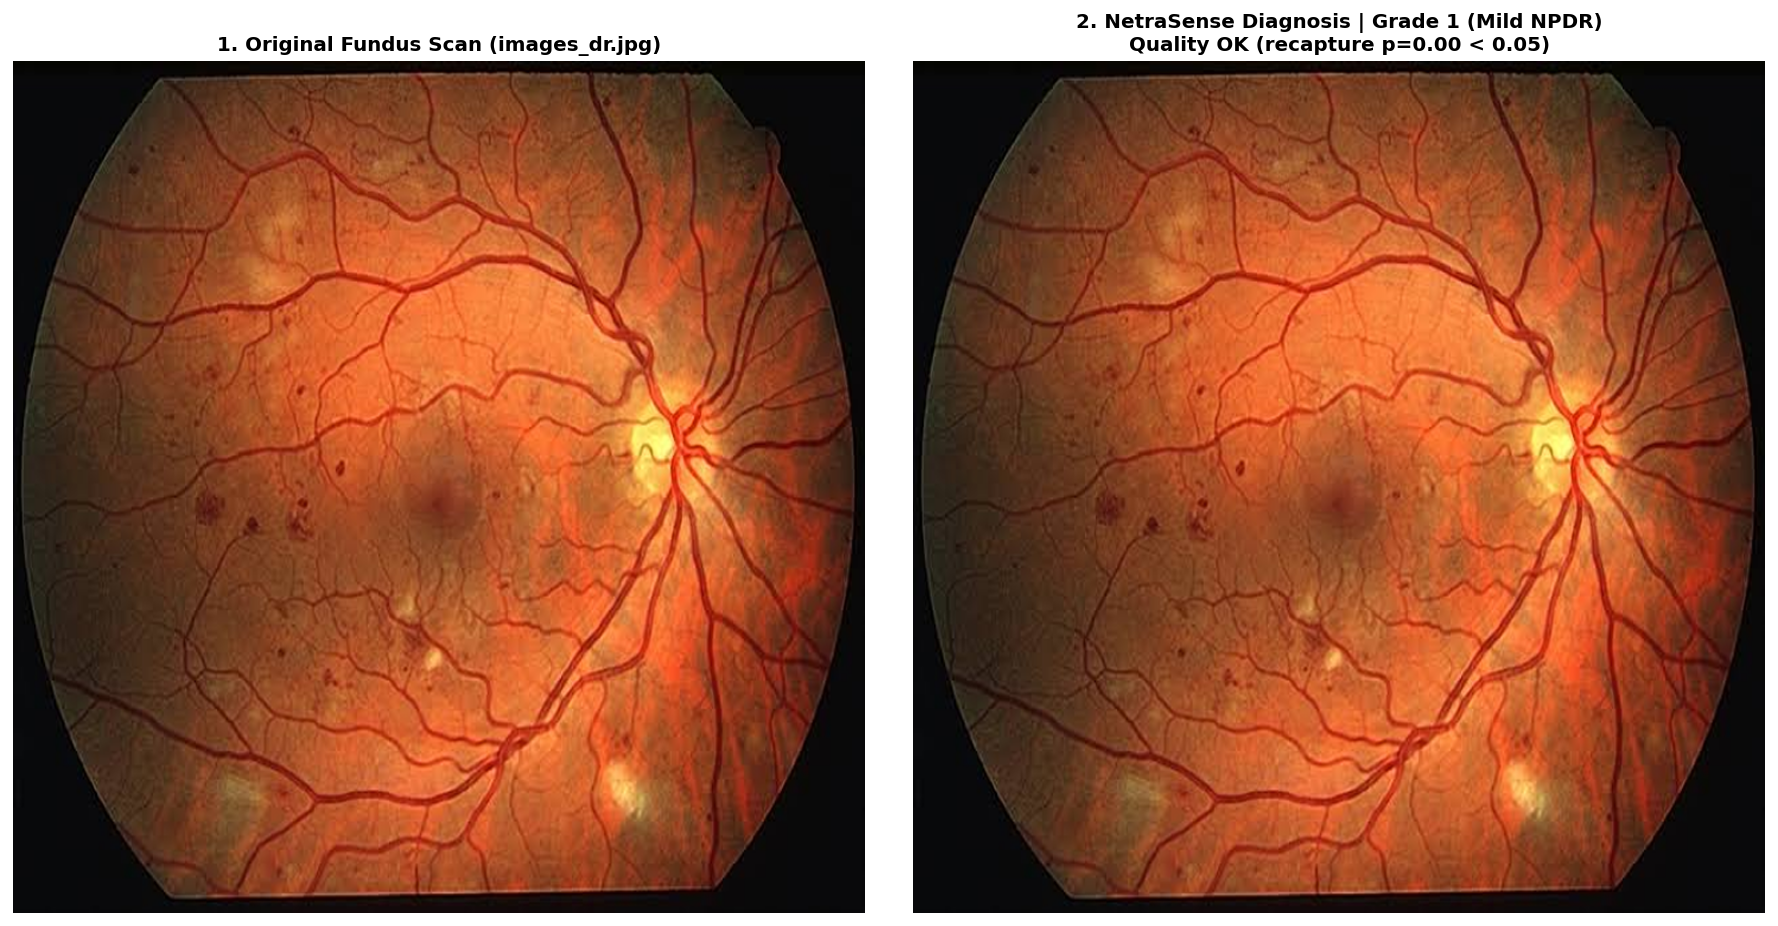

[Gate] recapture_prob=0.000 threshold=0.05 -> OK
[Main] grade=1 (Mild NPDR) | probs=[0.14800000190734863, 0.2630000114440918, 0.23600000143051147, 0.24199999868869781, 0.11100000143051147]


In [6]:
# AUTONOMOUS INFERENCE RECAPTURE GATE MODEL

def resolve_and_load_test_image(source):
    p = Path(str(source))
    if p.exists() and p.is_file():
        img_bgr = cv2.imread(str(p))
        if img_bgr is not None:
            return img_bgr, str(p)
    if p.exists() and p.is_dir():
        imgs = [f for f in p.rglob('*') if f.is_file() and f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        if imgs:
            img_bgr = cv2.imread(str(imgs[0]))
            if img_bgr is not None:
                return img_bgr, str(imgs[0])
    matches = [m for m in CFG.kaggle_input_dir.rglob('*') if m.is_file() and m.name.lower() == 'images_dr.jpg']
    if matches:
        return cv2.imread(str(matches[0])), str(matches[0])
    raise FileNotFoundError(f"Could not load test image: {source}")

def test_unannotated_image(model, image_source, recap_model=None):
    model.eval()
    img_bgr, resolved_path = resolve_and_load_test_image(image_source)

    vis_size = 768
    vis_rgb = cv2.cvtColor(cv2.resize(img_bgr, (vis_size, vis_size), interpolation=cv2.INTER_CUBIC), cv2.COLOR_BGR2RGB)
    img_rgb_384 = cv2.resize(vis_rgb, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_AREA)

    fov_768, lesion_roi_768, od_center_768, od_radius_768 = get_retinal_fov_and_od_mask(vis_rgb)

    gate = recapture_predict(recap_model, vis_rgb) if recap_model is not None else None

    transform = A.Compose([A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()])
    tensor = transform(image=img_rgb_384)['image'].unsqueeze(0).to(CFG.device)

    with torch.no_grad():
        with torch.amp.autocast('cuda' if torch.cuda.is_available() else 'cpu'):
            cls_logits, ma_logits, hemo_logits, ex_logits = model(tensor)
            probs = F.softmax(cls_logits, dim=1).cpu().numpy()[0]

    pred_grade = int(np.argmax(probs))

    fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=130)
    axes[0].imshow(vis_rgb)
    axes[0].set_title(f"1. Original Fundus Scan ({Path(resolved_path).name})", fontsize=11, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(vis_rgb)
    title = f"2. NetraSense Diagnosis | Grade {pred_grade} ({DR_CLASS_MAP[pred_grade][0]})"
    if gate is not None:
        if gate['recapture']:
            title = f"RECAPTURE REQUESTED ({', '.join(gate['reasons'])}) | p={gate['prob']:.2f}\nProvisional: Grade {pred_grade} ({DR_CLASS_MAP[pred_grade][0]}) - low confidence"
        else:
            title += f"\nQuality OK (recapture p={gate['prob']:.2f} < {gate['threshold']:.2f})"
    axes[1].set_title(title, fontsize=11, fontweight='bold', color=('crimson' if (gate and gate['recapture']) else 'black'))
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

    if gate is not None:
        print(f"[Gate] recapture_prob={gate['prob']:.3f} threshold={gate['threshold']:.2f} -> {'RETAKE' if gate['recapture'] else 'OK'}")
        for a in gate['advice']:
            print("   -", a)
    print(f"[Main] grade={pred_grade} ({DR_CLASS_MAP[pred_grade][0]}) | probs={np.round(probs, 3).tolist()}")
    return {'gate': gate, 'grade': pred_grade, 'probs': probs}

TEST_IMAGE_PATH = CFG.test_image_default
_ = test_unannotated_image(model, TEST_IMAGE_PATH, recap_model=recap_model)

In [7]:
# RLHF DOCTOR INTERFACE AND CLICK ANNOTATOR

import ipywidgets as widgets
from IPython.display import clear_output, display

RLHF_REQUIRE_GOOD_QUALITY = True
LESION_STYLE = {'ma': ('Microaneurysm', (0, 255, 255)), 'hemo': ('Hemorrhage', (255, 30, 30)), 'ex': ('Exudate', (255, 255, 0))}

class NetraSenseRLHFUpdater:
    def __init__(self, model: nn.Module, checkpoint_path: str, device=None, lr=1e-4, kl_beta=0.25):
        self.model = model
        self.checkpoint_path = checkpoint_path
        self.device = device if device is not None else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.kl_beta = kl_beta

        self.ref_model = copy.deepcopy(self.model).to(self.device)
        self.ref_model.eval()
        for param in self.ref_model.parameters():
            param.requires_grad = False

        for name, param in self.model.named_parameters():
            if any(k in name for k in ["classifier", "fuse1", "fuse2", "fuse3", "fuse4", "lesion_head", "backbone.blocks.6"]):
                param.requires_grad = True
            else:
                param.requires_grad = False

        self.optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, self.model.parameters()), lr=lr, weight_decay=1e-4)

    def update_weights_from_doctor(self, img_tensor, pred_grade, doctor_grade, missed_lesions=None, false_positives=None):
        self.model.eval()
        self.optimizer.zero_grad()
        img_tensor = img_tensor.to(self.device)

        cls_logits, ma_logits, hemo_logits, ex_logits = self.model(img_tensor)
        log_probs = F.log_softmax(cls_logits, dim=-1)
        probs = F.softmax(cls_logits, dim=-1)

        with torch.no_grad():
            ref_cls_logits, ref_ma, ref_hemo, ref_ex = self.ref_model(img_tensor)
            ref_probs = F.softmax(ref_cls_logits, dim=-1)

        if pred_grade == doctor_grade:
            reward_cls = 1.0
        else:
            severity_diff = abs(pred_grade - doctor_grade) / 4.0
            reward_cls = 1.5 + 3.0 * (severity_diff ** 2)

        target_action = torch.tensor([doctor_grade], dtype=torch.long, device=self.device)
        advantage_cls = reward_cls * (1.0 - probs[0, doctor_grade].detach())
        policy_loss_cls = (-advantage_cls * log_probs[0, target_action]).squeeze()

        lesion_map_dict = {"ma": ma_logits, "hemo": hemo_logits, "ex": ex_logits}
        spatial_policy_loss = torch.tensor(0.0, device=self.device)

        def create_gaussian_patch(cx_768, cy_768, radius=8):
            cx, cy = int(cx_768 * 0.5), int(cy_768 * 0.5)
            y_grid, x_grid = torch.meshgrid(torch.arange(384, device=self.device), torch.arange(384, device=self.device), indexing='ij')
            dist_sq = (x_grid - cx) ** 2 + (y_grid - cy) ** 2
            return (dist_sq <= radius ** 2).float().unsqueeze(0).unsqueeze(0)

        if missed_lesions:
            for item in missed_lesions:
                mask = create_gaussian_patch(item["x"], item["y"], radius=8)
                logits_map = lesion_map_dict[item["type"]]
                log_pi_pos = -F.binary_cross_entropy_with_logits(logits_map, torch.ones_like(logits_map), reduction='none')
                spatial_policy_loss += -2.5 * (log_pi_pos * mask).sum() / (mask.sum() + 1e-6)

        if false_positives:
            for item in false_positives:
                mask = create_gaussian_patch(item["x"], item["y"], radius=8)
                logits_map = lesion_map_dict[item["type"]]
                log_pi_neg = -F.binary_cross_entropy_with_logits(logits_map, torch.zeros_like(logits_map), reduction='none')
                spatial_policy_loss += -2.5 * (log_pi_neg * mask).sum() / (mask.sum() + 1e-6)

        kl_cls = F.kl_div(log_probs, ref_probs, reduction='batchmean')
        kl_lesions = (F.mse_loss(ma_logits, ref_ma) + F.mse_loss(hemo_logits, ref_hemo) + F.mse_loss(ex_logits, ref_ex)) * 0.1
        kl_penalty = self.kl_beta * (kl_cls + kl_lesions)

        total_rl_loss = policy_loss_cls + spatial_policy_loss + kl_penalty
        total_rl_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
        self.optimizer.step()

        torch.save({"model_state_dict": self.model.state_dict()}, self.checkpoint_path)

        with torch.no_grad():
            updated_cls_logits, _, _, _ = self.model(img_tensor)
            updated_conf = F.softmax(updated_cls_logits, dim=-1)[0, doctor_grade].item()

        return {
            "status": "success",
            "rl_loss": float(total_rl_loss.item()),
            "kl_penalty": float(kl_penalty.item()),
            "updated_confidence": float(updated_conf)
        }

class InteractiveRLHFInterface:
    def __init__(self, model, recap_model, image_path):
        self.model, self.recap = model, recap_model
        self._new_trainer()
        self.missed, self.fps = [], []
        self._build_ui()
        self.load(image_path)

    def _new_trainer(self):
        self.trainer = NetraSenseRLHFUpdater(model=self.model, checkpoint_path=CFG.rlhf_checkpoint_name, device=CFG.device, lr=5e-5, kl_beta=0.25)

    def load(self, path):
        img_bgr, self.path = resolve_and_load_test_image(path)
        self.vis_rgb = cv2.cvtColor(cv2.resize(img_bgr, (768, 768), interpolation=cv2.INTER_CUBIC), cv2.COLOR_BGR2RGB)
        img384 = cv2.resize(self.vis_rgb, (CFG.img_size, CFG.img_size), interpolation=cv2.INTER_AREA)
        tf = A.Compose([A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()])
        self.tensor = tf(image=img384)['image'].unsqueeze(0).to(CFG.device)
        self.fov768, self.roi768, self.od_center, self.od_radius = get_retinal_fov_and_od_mask(self.vis_rgb)
        self.gate = recapture_predict(self.recap, self.vis_rgb)
        self.missed.clear(); self.fps.clear()
        self._predict()
        self.grade.value = self.pred_grade
        self._refresh_display()

    def _predict(self):
        self.model.eval()
        with torch.no_grad():
            c, ma_logits, hemo_logits, ex_logits = self.model(self.tensor)
        self.probs = F.softmax(c, dim=-1).cpu().numpy()[0]
        self.pred_grade = int(self.probs.argmax())
        
        vis_size = 768
        ma_prob = F.interpolate(torch.sigmoid(ma_logits), size=(vis_size, vis_size), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
        hemo_prob = F.interpolate(torch.sigmoid(hemo_logits), size=(vis_size, vis_size), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
        ex_prob = F.interpolate(torch.sigmoid(ex_logits), size=(vis_size, vis_size), mode='bilinear', align_corners=False).squeeze().cpu().numpy()

        vessel_trunk_mask = extract_major_vessel_halo_mask(self.vis_rgb, self.fov768)
        vessel_ma_hemo_guard = cv2.dilate(vessel_trunk_mask, np.ones((3, 3), np.uint8))
        vessel_exudate_halo_guard = cv2.dilate(vessel_trunk_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))

        r, g, b = self.vis_rgb[:, :, 0].astype(np.float32), self.vis_rgb[:, :, 1].astype(np.float32), self.vis_rgb[:, :, 2].astype(np.float32)

        g_small_bg = cv2.GaussianBlur(g, (15, 15), 0)
        g_med_neutral = np.where(vessel_exudate_halo_guard > 0, cv2.medianBlur(self.vis_rgb[:, :, 1], 31).astype(np.float32), g)
        g_med_bg = cv2.GaussianBlur(g_med_neutral, (35, 35), 0)
        g_large_bg = cv2.GaussianBlur(g_med_neutral, (85, 85), 0)
        b_large_bg = cv2.GaussianBlur(b, (85, 85), 0)

        fovea_dir = -1 if self.od_center[0] > (vis_size // 2) else 1
        fovea_x = int(np.clip(self.od_center[0] + fovea_dir * (vis_size * 0.28), 50, vis_size - 50))
        fovea_y = int(np.clip(self.od_center[1] + (vis_size * 0.02), 50, vis_size - 50))
        fovea_guard = np.zeros((vis_size, vis_size), dtype=np.uint8)
        cv2.circle(fovea_guard, (fovea_x, fovea_y), int(vis_size * 0.032), 255, -1)

        dark_focal = np.clip(((g_small_bg - g) / (g_small_bg + 12.0)) * 3.8, 0.0, 1.0)
        ma_score = (0.45 * ma_prob + 0.55 * dark_focal) * (self.roi768 > 0) * (vessel_ma_hemo_guard == 0) * (fovea_guard == 0)

        rel_drop_med = (g_med_bg - g) / (g_med_bg + 12.0)
        rel_drop_large = (g_large_bg - g) / (g_large_bg + 12.0)
        multi_scale_dark = np.clip(np.maximum(rel_drop_med, rel_drop_large) * 3.6, 0.0, 1.0)
        red_dominance = np.clip((r - g) / (r * 0.35 + 15.0), 0.0, 1.0)
        dark_blot = multi_scale_dark * red_dominance
        hemo_score = (0.40 * hemo_prob + 0.60 * dark_blot) * (self.roi768 > 0) * (vessel_ma_hemo_guard == 0) * (fovea_guard == 0)

        hard_lipid = np.clip((g - g_med_bg) / 22.0, 0.0, 1.0) * np.clip((r - b) / 50.0, 0.0, 1.0) * (r > 135) * (g > 105) * (vessel_exudate_halo_guard == 0)
        soft_cws = (np.clip(((g - g_large_bg) / (g_large_bg + 15.0)) * 3.8, 0.0, 1.0) * np.clip((g - g_large_bg) / 18.0, 0.0, 1.0) * np.clip((b - b_large_bg + 4.0) / 14.0, 0.0, 1.0) * (r > 125) * (g > 95))
        bright_lesion = np.maximum(hard_lipid, soft_cws)
        ex_score = (0.40 * ex_prob + 0.60 * bright_lesion) * (self.roi768 > 0)

        annotated = self.vis_rgb.copy()
        cv2.circle(annotated, self.od_center, self.od_radius, (0, 255, 0), thickness=1, lineType=cv2.LINE_AA)

        mid_x, mid_y = vis_size // 2, vis_size // 2
        quad_hemo_ma = [0, 0, 0, 0]

        def register_quadrant(cx: int, cy: int):
            q_idx = (0 if cy < mid_y else 2) + (0 if cx < mid_x else 1)
            quad_hemo_ma[q_idx] += 1

        hemo_count = 0
        hemo_occupied = np.zeros((vis_size, vis_size), dtype=np.uint8)
        if np.any(self.roi768 > 0):
            hemo_thr = max(0.30, float(np.percentile(hemo_score[self.roi768 > 0], 98.2)))
            hemo_bin = (hemo_score >= hemo_thr).astype(np.uint8) * 255
            hemo_bin = cv2.morphologyEx(hemo_bin, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
            cnts_hemo, _ = cv2.findContours(hemo_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for c in cnts_hemo:
                area = cv2.contourArea(c)
                perim = cv2.arcLength(c, True)
                circ = (4 * np.pi * area / (perim * perim)) if perim > 0 else 0
                if 10 <= area <= 2800 and circ >= 0.14:
                    cv2.drawContours(annotated, [c], -1, (255, 30, 30), thickness=1, lineType=cv2.LINE_AA)
                    cv2.drawContours(hemo_occupied, [c], -1, 255, thickness=-1)
                    M = cv2.moments(c)
                    cx = int(M["m10"] / M["m00"]) if M["m00"] > 0 else mid_x
                    cy = int(M["m01"] / M["m00"]) if M["m00"] > 0 else mid_y
                    register_quadrant(cx, cy)
                    hemo_count += 1

        ma_count = 0
        if np.any(self.roi768 > 0):
            ma_thr = max(0.30, float(np.percentile(ma_score[self.roi768 > 0], 99.0)))
            ma_bin = ((ma_score >= ma_thr) & (hemo_occupied == 0)).astype(np.uint8) * 255
            cnts_ma, _ = cv2.findContours(ma_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            ma_cands = []
            for c in cnts_ma:
                area = cv2.contourArea(c)
                perim = cv2.arcLength(c, True)
                circ = (4 * np.pi * area / (perim * perim)) if perim > 0 else 0
                if 1 <= area <= 45 and circ >= 0.35:
                    (cx, cy), rad = cv2.minEnclosingCircle(c)
                    ma_cands.append((float(ma_score[int(cy), int(cx)]), int(cx), int(cy), int(np.clip(rad + 1, 2, 4))))
            ma_cands.sort(key=lambda x: x[0], reverse=True)
            for _, cx, cy, rad in ma_cands[:70]:
                cv2.circle(annotated, (cx, cy), rad, (0, 255, 255), thickness=1, lineType=cv2.LINE_AA)
                register_quadrant(cx, cy)
                ma_count += 1

        ex_count = 0
        if np.any(self.roi768 > 0):
            ex_thr = max(0.32, float(np.percentile(ex_score[self.roi768 > 0], 98.8)))
            ex_bin = (ex_score >= ex_thr).astype(np.uint8) * 255
            ex_bin = cv2.morphologyEx(ex_bin, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
            cnts_ex, _ = cv2.findContours(ex_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for c in cnts_ex:
                area = cv2.contourArea(c)
                perim = cv2.arcLength(c, True)
                circ = (4 * np.pi * area / (perim * perim)) if perim > 0 else 0
                if 4 <= area <= 3500 and circ >= 0.14:
                    cv2.drawContours(annotated, [c], -1, (255, 255, 0), thickness=1, lineType=cv2.LINE_AA)
                    ex_count += 1

        self.overlay = annotated
        self.ma_count, self.hemo_count, self.ex_count = ma_count, hemo_count, ex_count

    def _build_ui(self):
        W = widgets
        self.path_box = W.Text(value=CFG.test_image_default, description='Image', layout=W.Layout(width='520px'))
        self.btn_load = W.Button(description='Load Image', button_style='info')
        self.grade = W.Dropdown(options=[(f"{i} - {DR_CLASS_MAP[i][0]}", i) for i in range(5)], description="Doctor Grade")
        self.ltype = W.ToggleButtons(options=[('Microaneurysm (MA)', 'ma'), ('Hemorrhage (Hemo)', 'hemo'), ('Exudate (Ex)', 'ex')], description='Active Tool')
        self.override = W.Checkbox(value=False, description='Override quality guard', indent=False)
        self.steps = W.IntSlider(value=3, min=1, max=5, description='RL Steps')
        self.b_clear = W.Button(description='Clear All Marks', button_style='warning')
        self.b_run = W.Button(description='Run RLHF Weight Update', button_style='danger')
        self.b_reset = W.Button(description='Reset to Base Weights')
        
        self.info = W.HTML()
        self.canvas_output = W.Output()
        self.log_output = W.Output()

        self.btn_load.on_click(lambda _: self.load(self.path_box.value))
        self.b_clear.on_click(self._clear_clicks)
        self.b_run.on_click(self._run_rlhf)
        self.b_reset.on_click(self._reset_weights)

        self.ui = W.VBox([
            W.HBox([self.path_box, self.btn_load]),
            self.info,
            W.HBox([self.grade, self.ltype]),
            W.HBox([self.override, self.steps, self.b_clear]),
            W.HBox([self.b_run, self.b_reset]),
            self.canvas_output,
            self.log_output
        ])

    def _refresh_display(self):
        g = self.gate
        gate_txt = (f"<b style='color:crimson'>RECAPTURE: {', '.join(g['reasons'])}</b>" if g['recapture'] else "<b style='color:green'>Quality OK</b>")
        self.info.value = (f"<b>AI Grade Prediction: {self.pred_grade} ({DR_CLASS_MAP[self.pred_grade][0]})</b> | Probs: {np.round(self.probs, 3).tolist()}"
                           f"<br>MAs: {self.ma_count} [Cyan] | Hemorrhages: {self.hemo_count} [Red] | Exudates: {self.ex_count} [Yellow] | OD [Green]"
                           f"<br>Quality Gate: p={g['prob']:.2f} (thr {g['threshold']:.2f}) | {gate_txt}"
                           f"<br><b>Instructions:</b> Left-Click on image = Add <b>Missed (+)</b> | Right-Click on image = Add <b>False Positive (x)</b>"
                           f"<br><b>Current Marks:</b> {len(self.missed)} missed lesions, {len(self.fps)} false positives.")
        
        with self.canvas_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(8, 8), dpi=110)
            ax.imshow(self.overlay)
            
            for m in self.missed:
                ax.scatter([m['x']], [m['y']], c='lime', s=90, marker='+', linewidths=2.5)
                ax.text(m['x'] + 6, m['y'] - 6, f"+{m['type']}", color='lime', fontsize=8, fontweight='bold')
            for m in self.fps:
                ax.scatter([m['x']], [m['y']], c='magenta', s=80, marker='x', linewidths=2.5)
                ax.text(m['x'] + 6, m['y'] - 6, f"x{m['type']}", color='magenta', fontsize=8, fontweight='bold')

            ax.set_title("Ophthalmologist Click Canvas\n(Cyan=MA | Red=Hemorrhage | Yellow=Exudate | Green=OD)", fontsize=10, fontweight='bold')
            ax.axis('off')

            def onclick(event):
                if event.xdata is not None and event.ydata is not None:
                    x, y = int(event.xdata), int(event.ydata)
                    lt = self.ltype.value
                    if event.button == 1:  # Left click
                        self.missed.append({"type": lt, "x": x, "y": y})
                        print(f"[Left-Click] Added Missed {lt.upper()} at (x={x}, y={y})")
                    elif event.button == 3:  # Right click
                        self.fps.append({"type": lt, "x": x, "y": y})
                        print(f"[Right-Click] Added False Positive {lt.upper()} at (x={x}, y={y})")
                    self._refresh_display()

            fig.canvas.mpl_connect('button_press_event', onclick)
            plt.show()

    def _clear_clicks(self, _):
        self.missed.clear()
        self.fps.clear()
        self._refresh_display()

    def _run_rlhf(self, _):
        with self.log_output:
            clear_output()
            if RLHF_REQUIRE_GOOD_QUALITY and self.gate['recapture'] and not self.override.value:
                print("BLOCKED: Quality gate flagged this image for recapture. Tick 'Override quality guard' to force training.")
                return
            doc_grade = int(self.grade.value)
            before_conf = float(self.probs[doc_grade])
            
            for _ in range(int(self.steps.value)):
                res = self.trainer.update_weights_from_doctor(self.tensor, self.pred_grade, doc_grade, list(self.missed), list(self.fps))
            
            self._predict()
            print("-" * 60)
            print(f"RLHF UPDATE SUCCESSFUL ({self.steps.value} optimization steps)")
            print(f" - Total Loss: {res['rl_loss']:.4f} | KL Anchor Penalty: {res['kl_penalty']:.4f}")
            print(f" - P(Grade {doc_grade}): {before_conf*100:.1f}% -> {float(self.probs[doc_grade])*100:.1f}%")
            print(f" - Updated Checkpoint Saved To: {CFG.rlhf_checkpoint_name}")
            print("-" * 60)
            self.missed.clear(); self.fps.clear()
            self._refresh_display()

    def _reset_weights(self, _):
        with self.log_output:
            clear_output()
            ck = torch.load(CFG.checkpoint_name, map_location=CFG.device, weights_only=False)
            self.model.load_state_dict(ck['model_state_dict'])
            self.model.eval()
            self._new_trainer()
            self._predict()
            self._refresh_display()
            print("Model successfully reset to base best-QWK weights; RL reference model re-initialized.")

rlhf_ui = InteractiveRLHFInterface(model, recap_model, TEST_IMAGE_PATH)
display(rlhf_ui.ui)

In [9]:
# WEIGHT FILES SUMMARY

for label, fname in [("Model A  (main, best QWK)", CFG.checkpoint_name),
                     ("Model A+ (after RLHF)", CFG.rlhf_checkpoint_name),
                     ("Model B (recapture gate)", CFG.recap_checkpoint_name)]:
    path = fname if os.path.exists(fname) else f"/kaggle/working/{fname}"
    if os.path.exists(path):
        print(f"{label:28s}: {path}  ({os.path.getsize(path) / (1024 * 1024):.2f} MB)")
        display(FileLink(fname))
    else:
        print(f"{label:28s}: not found ({fname})")

Model A  (main, best QWK)   : netrasense_efficientnet_b3_best.pth  (43.94 MB)


/kaggle/working/netrasense_efficientnet_b3_best.pth

Model A+ (after RLHF)       : netrasense_efficientnet_b3_rlhf.pth  (43.94 MB)


/kaggle/working/netrasense_efficientnet_b3_rlhf.pth

Model B (recapture gate)    : netrasense_recapture_gate.pth  (16.88 MB)


/kaggle/working/netrasense_recapture_gate.pth